# HotelIQ – Feature Selection

## Objective

The objective of this notebook is to identify and select relevant features for predicting hotel booking cancellations.

### Activities Performed
- Loaded the cleaned hotel booking dataset.
- Examined the target variable distribution.
- Identified numerical and categorical features.
- Analysed numerical features against booking cancellations.
- Examined categorical feature cancellation rates.
- Studied correlations between numerical features.
- Identified potential data leakage.
- Finalised features based on the booking-time prediction scenario.

### Prediction Objective

The goal is to predict whether a hotel booking is likely to be cancelled using information available at the time of booking.

**Target Variable:** `is_canceled`

- `0` – Not Cancelled
- `1` – Cancelled

In [2]:
import pandas as pd
import numpy as np
pd.set_option('display.max_columns',None)

In [3]:
df = pd.read_csv('../data/hotel_bookings_cleaned.csv')

print("Dataset Shape", df.shape)

Dataset Shape (87395, 31)


In [4]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,-1.0,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,-1.0,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,-1.0,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [5]:
df['is_canceled'].value_counts()

is_canceled
0    63370
1    24025
Name: count, dtype: int64

In [6]:
df['is_canceled'].value_counts(normalize=True)*100

is_canceled
0    72.509869
1    27.490131
Name: proportion, dtype: float64

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 87395 entries, 0 to 87394
Data columns (total 31 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           87395 non-null  str    
 1   is_canceled                     87395 non-null  int64  
 2   lead_time                       87395 non-null  int64  
 3   arrival_date_year               87395 non-null  int64  
 4   arrival_date_month              87395 non-null  str    
 5   arrival_date_week_number        87395 non-null  int64  
 6   arrival_date_day_of_month       87395 non-null  int64  
 7   stays_in_weekend_nights         87395 non-null  int64  
 8   stays_in_week_nights            87395 non-null  int64  
 9   adults                          87395 non-null  int64  
 10  children                        87395 non-null  float64
 11  babies                          87395 non-null  int64  
 12  meal                            87395 non-n

In [8]:
df.isnull().sum()[df.isnull().sum() > 0]

Series([], dtype: int64)

## Feature Selection

The objective of this stage is to identify relevant features for predicting hotel booking cancellations.

Feature selection will be based on:
- Domain knowledge
- Data distribution and statistical relationships
- Correlation analysis
- Model-based feature importance

Columns that directly reveal the booking outcome will be excluded to prevent data leakage.

In [9]:
# Remove columns that should not be used as model features
X = df.drop(
    columns=['is_canceled',
             'reservation_status',
             'reservation_status_date'])

# Target variable
y = df['is_canceled']

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (87395, 28)
Target Shape: (87395,)


In [10]:
numerical_columns = X.select_dtypes(include=['int64','float64']).columns

categorical_columns = X.select_dtypes(include=['str','object','category']).columns

print("Numerical Columns",len(numerical_columns))

print("Categorical Columns",len(categorical_columns))

print("\nNumerical Features:")
print(list(numerical_columns))

print("\nCategorical Features:")
print(list(categorical_columns))

Numerical Columns 18
Categorical Columns 10

Numerical Features:
['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Categorical Features:
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type']


#### Numerical Feature Analysis

In [11]:
numerical_analysis = df.groupby('is_canceled')[numerical_columns].mean().T

numerical_analysis.columns = ['Not Canceled', 'Canceled']

numerical_analysis

,Not Canceled,Canceled
lead_time,70.097617,105.719251
arrival_date_year,2016.173095,2016.308387
arrival_date_week_number,26.826448,26.870385
arrival_date_day_of_month,15.786729,15.891988
stays_in_weekend_nights,0.966972,1.106139
stays_in_week_nights,2.520483,2.901977
adults,1.844232,1.959043
children,0.119725,0.188512
babies,0.012261,0.007034
is_repeated_guest,0.049755,0.010864


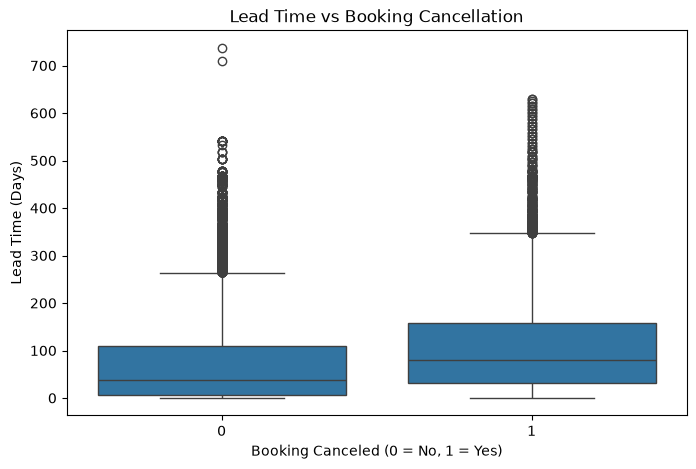

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='is_canceled', y='lead_time')

plt.title('Lead Time vs Booking Cancellation')
plt.xlabel('Booking Canceled (0 = No, 1 = Yes)')
plt.ylabel('Lead Time (Days)')

plt.show()

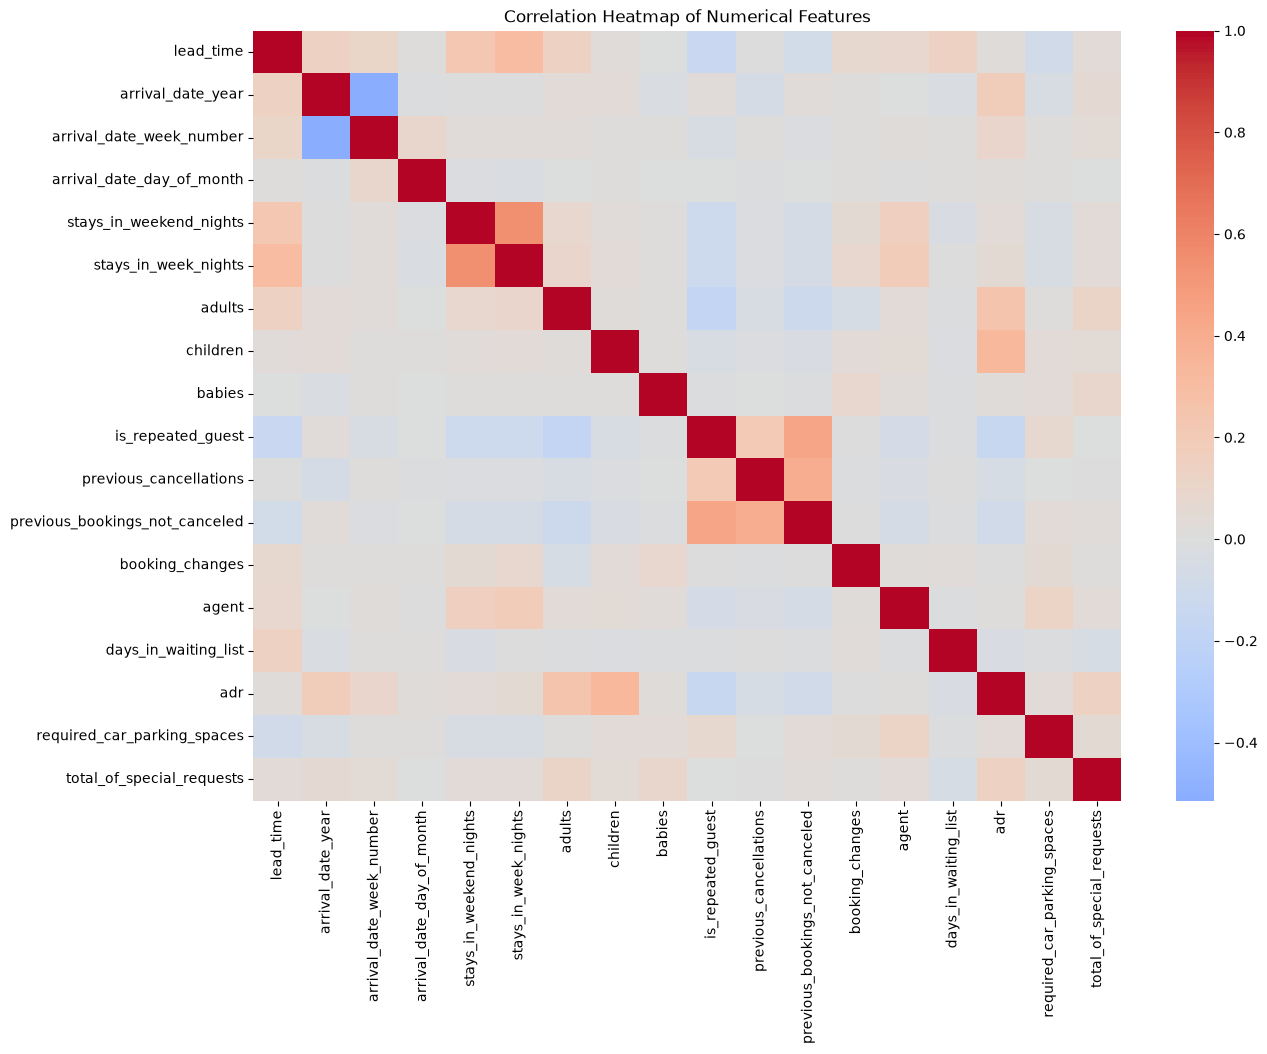

In [13]:
correlation_matrix = df[numerical_columns].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(correlation_matrix, cmap='coolwarm', 
            center=0, annot=False)

plt.title('Correlation Heatmap of Numerical Features')
plt.show()

#### Categorical Feature Analysis

In [14]:
for col in categorical_columns:

    print(f"\n{'='*60}")
    print(f"Cancellation Analysis: {col}")
    print('='*60)

    analysis = (df.groupby(col, observed=True)['is_canceled']
                .agg(total_bookings='count',
                     canceled_bookings='sum',
                     cancellation_rate='mean').reset_index())

    analysis['cancellation_rate'] *= 100

    # Show categories with at least 100 bookings
    analysis = analysis[analysis['total_bookings'] >= 100]

    analysis = analysis.sort_values('cancellation_rate', ascending=False)

    #print(analysis.to_string(index=False))
    display(analysis)


Cancellation Analysis: hotel


,hotel,total_bookings,canceled_bookings,cancellation_rate
0,City Hotel,53428,16049,30.038557
1,Resort Hotel,33967,7976,23.481615



Cancellation Analysis: arrival_date_month


,arrival_date_month,total_bookings,canceled_bookings,cancellation_rate
1,August,11257,3623,32.184419
5,July,10057,3198,31.798747
0,April,7908,2409,30.462822
6,June,7765,2354,30.315518
8,May,8355,2442,29.228007
2,December,5131,1378,26.856363
11,September,6690,1642,24.544096
7,March,7512,1830,24.361022
10,October,6934,1642,23.680415
3,February,6098,1415,23.204329



Cancellation Analysis: meal


,meal,total_bookings,canceled_bookings,cancellation_rate
3,SC,9481,3347,35.302183
1,FB,360,99,27.500000
2,HB,9085,2450,26.967529
0,BB,67977,18047,26.548686
4,Undefined,492,82,16.666667


... (10 outputs left out)


Cancellation Analysis: deposit_type


,deposit_type,total_bookings,canceled_bookings,cancellation_rate
1,Non Refund,1038,983,94.701349
0,No Deposit,86250,23016,26.685217
2,Refundable,107,26,24.299065



Cancellation Analysis: customer_type


,customer_type,total_bookings,canceled_bookings,cancellation_rate
2,Transient,71986,21672,30.105854
0,Contract,3139,512,16.310927
3,Transient-Party,11726,1787,15.239638
1,Group,544,54,9.926471


In [15]:
# Columns unavailable or unsuitable for booking-time prediction
drop_columns = ['is_canceled',
                'reservation_status',
                'reservation_status_date',
                'booking_changes',
                'assigned_room_type',
                'days_in_waiting_list']

# Feature variables
X = df.drop(columns=drop_columns)

# Target variable
y = df['is_canceled']

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nRemaining Features:")
print(X.columns.tolist())

Feature Shape: (87395, 25)
Target Shape: (87395,)

Remaining Features:
['hotel', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


In [16]:
pd.crosstab(df['market_segment'],df['distribution_channel'],
            normalize='index').round(3)

distribution_channel,Corporate,Direct,GDS,TA/TO,Undefined
market_segment,,,,,
Aviation,0.956,0.000,0.000,0.044,0.0
Complementary,0.115,0.778,0.000,0.107,0.0
Corporate,0.927,0.037,0.000,0.037,0.0
Direct,0.007,0.973,0.000,0.019,0.0
Groups,0.135,0.132,0.000,0.733,0.0
Offline TA/TO,0.007,0.001,0.003,0.989,0.0
Online TA,0.001,0.003,0.003,0.994,0.0
Undefined,0.000,0.000,0.000,0.000,1.0


In [17]:
categorical_features = ['hotel', 'arrival_date_month',
                        'meal', 'country', 'market_segment',
                        'distribution_channel', 'reserved_room_type',
                        'deposit_type', 'customer_type', 'agent']

numerical_features = [col for col in X.columns 
                      if col not in categorical_features]

print("Numerical Features", len(numerical_features))
print("Categorical Features", len(categorical_features))

Numerical Features 15
Categorical Features 10


## Feature Selection – Summary

### Dataset Overview

- Total Records: 87,395
- Total Original Features: 31
- Target Variable: `is_canceled`
- Not Cancelled: 72.51%
- Cancelled: 27.49%

### Data Leakage Prevention

The following columns were excluded from model training:

| Column | Reason |
|---|---|
| `is_canceled` | Target variable |
| `reservation_status` | Directly reveals booking outcome |
| `reservation_status_date` | Contains information about the final reservation status |
| `booking_changes` | Can change after the initial booking |
| `assigned_room_type` | Represents the actual assigned room, which may differ from the reserved room |
| `days_in_waiting_list` | May contain information unavailable at the initial booking stage |

### Final Selected Features

After feature selection, the dataset contains:

- Numerical Features: 15
- Categorical Features: 10
- Total Selected Features: 25

The `agent` column is treated as categorical because it represents an agent identifier rather than a continuous numerical measurement.

### Additional Observations

- Lead time showed a noticeable difference between cancelled and non-cancelled bookings.
- Cancellation rates varied across hotel types, market segments, distribution channels, and deposit types.
- Market segment and distribution channel showed a strong relationship, so both are retained initially for model comparison.
- High-cardinality categorical features such as country and agent will require appropriate encoding during preprocessing.

### Conclusion

The feature-selection stage is complete. The final dataset contains 25 selected features suitable for the booking-time cancellation prediction objective.

The next stage will focus on train-test splitting, categorical encoding, numerical scaling, and preparing the data for machine learning models.